# 05 — Correlação, regressão e por que correlação ≠ causação

> **stats-foundations · Fase 1** — medir e modelar relações entre variáveis, e reconhecer a armadilha causal.

A pergunta clássica de tráfego: *"gastar mais **causa** mais vendas?"*. Este notebook cobre as três
camadas dessa pergunta:

1. **Correlação** — existe associação entre gasto e receita? Quão forte?
2. **Regressão linear simples** — quantificar: cada R$1 a mais de gasto associa-se a quanto de receita?
3. **A armadilha** — por que uma correlação forte **não prova** causa (confundidores), e como isso
   prepara a inferência causal da Fase 3.

## Setup e dados sintéticos

Simulo 90 dias de uma campanha. Importante: incluí um **confundidor** — a *sazonalidade* (fins de
semana e datas quentes) — que aumenta **tanto** o gasto **quanto** a demanda orgânica. Isso vai inflar
a correlação entre gasto e receita.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(42)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

n_dias = 90
# confundidor: "calor" do dia (sazonalidade/demanda) — não observado diretamente
calor = RNG.normal(0, 1, n_dias)

# gasto: decisão do gestor sobe nos dias quentes (mais demanda => mais budget)
gasto = 1000 + 250 * calor + RNG.normal(0, 120, n_dias)
gasto = np.clip(gasto, 300, None)

# receita: efeito REAL do gasto (R$ 2,5 por R$1) + efeito do calor (demanda orgânica) + ruído
efeito_real_gasto = 2.5
receita = 1500 + efeito_real_gasto * gasto + 900 * calor + RNG.normal(0, 600, n_dias)

print(f"{n_dias} dias simulados.")
print(f"Gasto médio: R$ {gasto.mean():,.0f}/dia | Receita média: R$ {receita.mean():,.0f}/dia")
print(f"(efeito causal REAL do gasto, plantado: R$ {efeito_real_gasto:.1f} por R$1)")

90 dias simulados.
Gasto médio: R$ 988/dia | Receita média: R$ 3,972/dia
(efeito causal REAL do gasto, plantado: R$ 2.5 por R$1)


## A. Correlação: existe associação?

**Pearson** mede associação *linear*; **Spearman** mede associação *monotônica* (robusta a outliers e
relações curvas). Valores perto de ±1 = associação forte; perto de 0 = fraca.

Correlação de Pearson : 0.866  (p=3.7e-28)
Correlação de Spearman: 0.896  (p=9.1e-33)
=> associação forte e positiva entre gasto e receita.


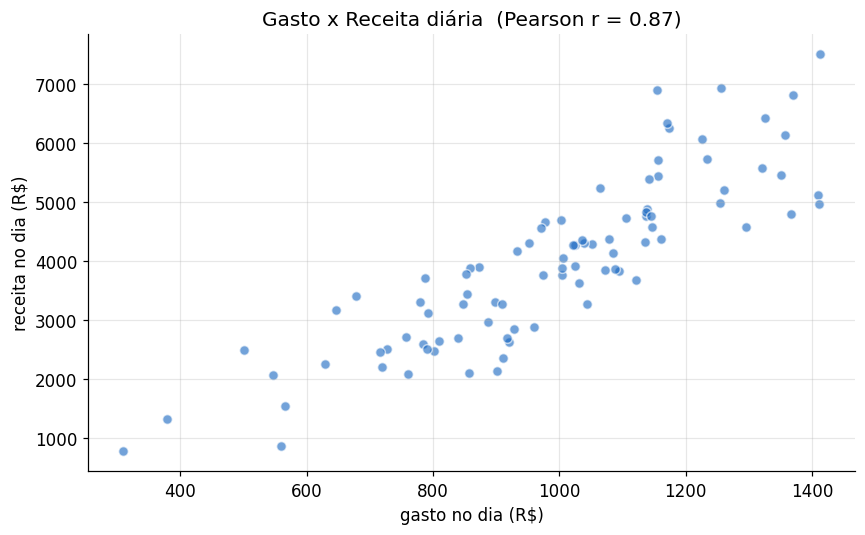

In [2]:
r_pearson, p_p = stats.pearsonr(gasto, receita)
r_spearman, p_s = stats.spearmanr(gasto, receita)

print(f"Correlação de Pearson : {r_pearson:.3f}  (p={p_p:.1e})")
print(f"Correlação de Spearman: {r_spearman:.3f}  (p={p_s:.1e})")
print("=> associação forte e positiva entre gasto e receita.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(gasto, receita, s=40, color="#1565c0", alpha=0.6, edgecolor="white")
ax.set_title(f"Gasto x Receita diária  (Pearson r = {r_pearson:.2f})")
ax.set_xlabel("gasto no dia (R$)"); ax.set_ylabel("receita no dia (R$)")
fig.tight_layout(); plt.show()

## B. Regressão linear simples: quantificar a relação

A reta de mínimos quadrados resume a relação: `receita ≈ a + b · gasto`. O coeficiente **b** (inclinação)
é o que mais interessa, e o **R²** diz quanta da variação da receita a reta explica.

Inclinação (b): 5.20   => cada R$1 de gasto ASSOCIA-SE a R$ 5.20 de receita
Intercepto (a): -1,167
R²: 0.749   => a reta explica 75% da variação da receita
p-valor da inclinação: 3.7e-28


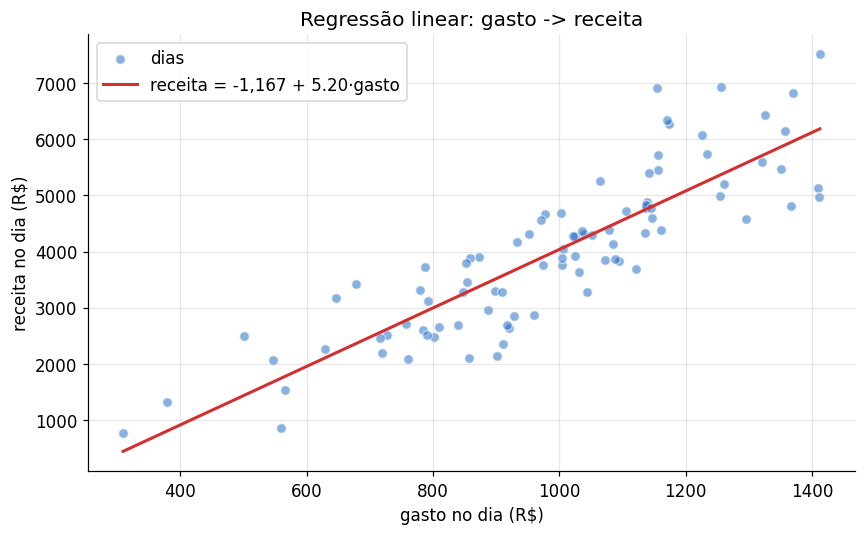

In [3]:
reg = stats.linregress(gasto, receita)
print(f"Inclinação (b): {reg.slope:.2f}   => cada R$1 de gasto ASSOCIA-SE a R$ {reg.slope:.2f} de receita")
print(f"Intercepto (a): {reg.intercept:,.0f}")
print(f"R²: {reg.rvalue**2:.3f}   => a reta explica {reg.rvalue**2:.0%} da variação da receita")
print(f"p-valor da inclinação: {reg.pvalue:.1e}")

xs = np.linspace(gasto.min(), gasto.max(), 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(gasto, receita, s=40, color="#1565c0", alpha=0.5, edgecolor="white", label="dias")
ax.plot(xs, reg.intercept + reg.slope * xs, color="#d32f2f", lw=2,
        label=f"receita = {reg.intercept:,.0f} + {reg.slope:.2f}·gasto")
ax.set_title("Regressão linear: gasto -> receita")
ax.set_xlabel("gasto no dia (R$)"); ax.set_ylabel("receita no dia (R$)")
ax.legend()
fig.tight_layout(); plt.show()

## C. A armadilha: correlação ≠ causação

A regressão acima estimou a inclinação **bem acima** do efeito causal real que plantei (R$ 2,5). Por quê?
Porque o **confundidor "calor"** empurra gasto **e** receita para cima ao mesmo tempo. A regressão simples
credita ao gasto um efeito que, em parte, é da sazonalidade.

Quando eu **controlo** o confundidor (regressão múltipla incluindo o calor), a estimativa do efeito do
gasto volta para perto da verdade. É um aperitivo da **inferência causal** (Fase 3).

In [4]:
# Regressão MÚLTIPLA controlando o confundidor: receita ~ gasto + calor
# (mínimos quadrados via numpy; sem libs extras)
X = np.column_stack([np.ones(n_dias), gasto, calor])  # intercepto, gasto, calor
coef, *_ = np.linalg.lstsq(X, receita, rcond=None)
b_intercepto, b_gasto, b_calor = coef

print("Estimativa do efeito do GASTO sobre a receita (R$ por R$1):")
print(f"  - regressão SIMPLES (sem controlar calor): {stats.linregress(gasto, receita).slope:.2f}  <- inflada")
print(f"  - regressão MÚLTIPLA (controlando calor) : {b_gasto:.2f}  <- perto do real (2,5)")
print(f"  - verdade plantada                       : 2.50")
print(f"\n(efeito estimado do confundidor 'calor': {b_calor:,.0f})")
print("\nLição: a correlação/regressão simples confundiu efeito do gasto com sazonalidade.")

Estimativa do efeito do GASTO sobre a receita (R$ por R$1):
  - regressão SIMPLES (sem controlar calor): 5.20  <- inflada
  - regressão MÚLTIPLA (controlando calor) : 2.56  <- perto do real (2,5)
  - verdade plantada                       : 2.50

(efeito estimado do confundidor 'calor': 943)

Lição: a correlação/regressão simples confundiu efeito do gasto com sazonalidade.


## Resumo

| Conceito | O que diz | Cuidado |
|---|---|---|
| **Correlação** (Pearson/Spearman) | força da associação | associação ≠ causa |
| **Regressão simples** | quantifica a relação (inclinação, R²) | enviesada se há confundidor omitido |
| **Regressão múltipla** | controla outras variáveis | só controla o que você **mede** |
| **Causalidade** | efeito de *intervir* numa variável | exige método causal (Fase 3) |

**Aplicação em tráfego:** não basta ver que dias de maior gasto têm maior receita para concluir que o
gasto *causou* a receita — sazonalidade, promoções e demanda orgânica confundem. Medir o **efeito
incremental real** de uma campanha é o tema da **Fase 3** (inferência causal e Marketing Mix Modeling).

**Marco:** com este notebook, o repositório `stats-foundations` fecha os **5 notebooks** previstos como
entregável da Fase 1. ✅